# XGBoost

XGBoost fits regularised trees using gradient and curvature information from the loss. This run uses squared error in MPa.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from gallery.tabular import concrete_split, regression_report

model = XGBRegressor(
    n_estimators=140,
    max_depth=4,
    learning_rate=0.07,
    objective="reg:squarederror",
    n_jobs=1,
    random_state=17,
)

## Data and split

All ages of a concrete recipe stay in the same partition. Five training folds also keep recipes together. The final test uses unseen mixes.

In [3]:
X, X_test, y, y_test, groups = concrete_split()

## Held-out predictions

The table includes a training-only baseline. Both panels use the untouched test observations.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.867, MAE 4.38 MPa
                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.858      4.708       6.507            3.314                  -1.601
Training mean -0.002     14.236      17.267           13.145                  -0.829


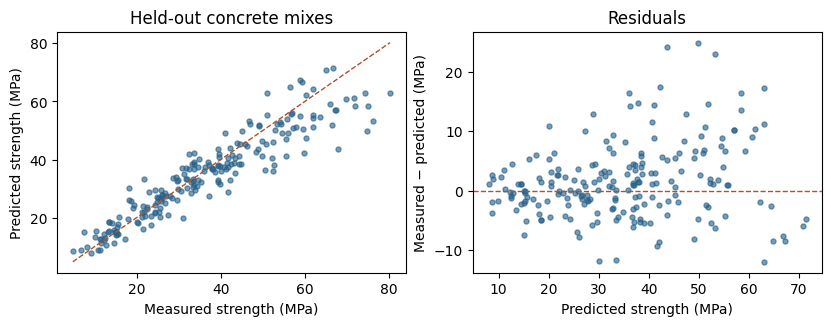

In [4]:
predictions = regression_report(model, X, X_test, y, y_test, groups)
plt.show()

## Reading the result

The residual plot shows where the fixed tree depth and shrinkage leave systematic error.

## References

[Chen and Guestrin, XGBoost (2016)](https://doi.org/10.1145/2939672.2939785)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)